# Diwali Sales Analysis
Exploratory data analysis on Diwali retail sales: data cleaning, then who buys what, where, and how much.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

## 2. Load and inspect

In [2]:
df = pd.read_csv('../data/Diwali_Sales_Data.csv', encoding='latin-1')
df.shape

(11251, 15)

In [3]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.3 MB


In [5]:
df.isnull().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11251
unnamed1            11251
dtype: int64

## 3. Clean
`Status` and `unnamed1` are fully empty, so drop them. Then drop rows with a missing `Amount` and remove duplicates.

In [6]:
df.drop(columns=['Status', 'unnamed1'], inplace=True)
df.dropna(inplace=True)
print('after dropping missing:', df.shape)
print('duplicates:', df.duplicated().sum())
df.drop_duplicates(inplace=True)
print('after dropping duplicates:', df.shape)

after dropping missing: (11239, 13)
duplicates: 8
after dropping duplicates: (11231, 13)


In [7]:
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123100e+04,11231.000000,11231.000000,11231.000000,11231.000000
mean,1.003004e+06,35.411985,0.419998,2.489093,9454.084982
std,1.716055e+03,12.756116,0.493580,1.114880,5221.728776
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003065e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004428e+06,43.000000,1.000000,3.000000,12677.500000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


## 4. Key numbers

In [8]:
total = df['Amount'].sum()
print(f'Total sales: Rs {total:,.0f}  (about Rs {total/1e7:.1f} crore)')
print(f'Average order amount: Rs {df["Amount"].mean():,.0f}')
print('Unique customers:', df['User_ID'].nunique())
print('States:', df['State'].nunique(), '| Product categories:', df['Product_Category'].nunique())

Total sales: Rs 106,178,828  (about Rs 10.6 crore)
Average order amount: Rs 9,454
Unique customers: 3752
States: 16 | Product categories: 18


## 5. Who buys? Gender and age group

Gender
F    70.0
M    30.0
Name: Amount, dtype: float64


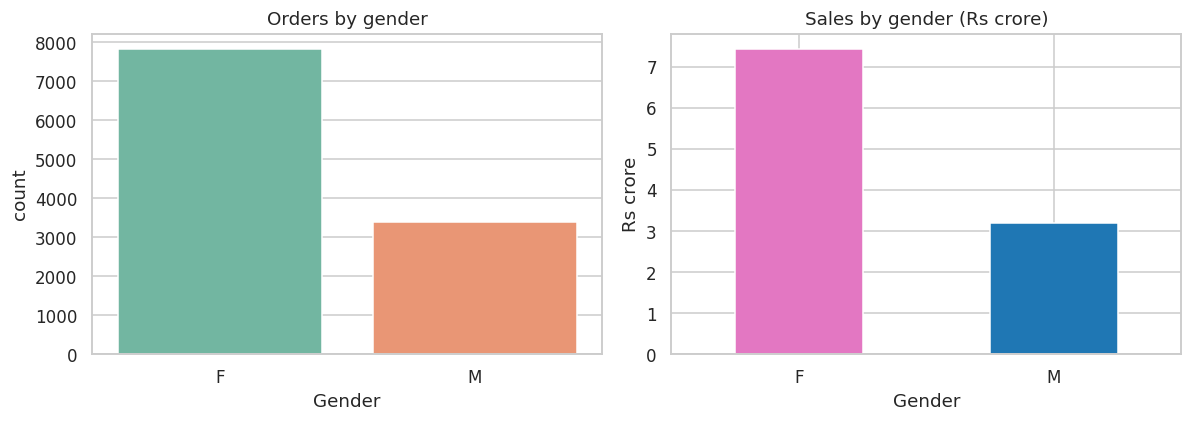

In [9]:
gender_sales = df.groupby('Gender')['Amount'].sum()
print((gender_sales / total * 100).round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='Gender', ax=ax[0], palette='Set2', hue='Gender', legend=False)
ax[0].set_title('Orders by gender')
(gender_sales/1e7).plot(kind='bar', ax=ax[1], color=['#e377c2','#1f77b4'], rot=0)
ax[1].set_title('Sales by gender (Rs crore)'); ax[1].set_ylabel('Rs crore')
plt.tight_layout(); plt.savefig('../images/01_gender.png'); plt.show()

Age Group
0-17      2.5
18-25    16.2
26-35    40.1
36-45    20.8
46-50     8.7
51-55     7.8
55+       3.8
Name: Amount, dtype: float64


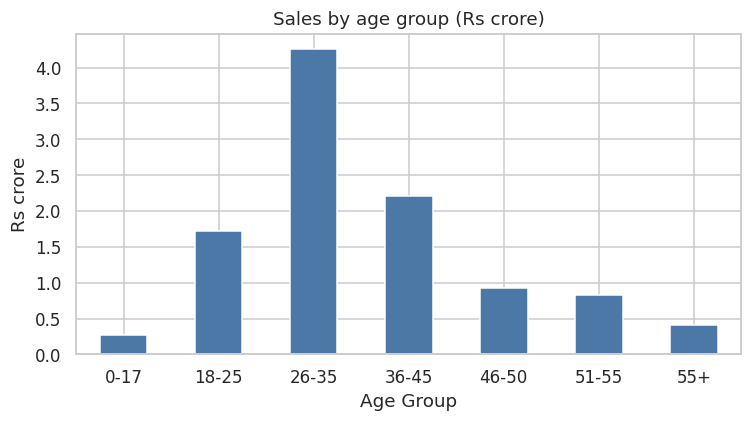

In [10]:
age_sales = df.groupby('Age Group')['Amount'].sum().sort_index()
print((age_sales / total * 100).round(1))

plt.figure(figsize=(7, 4))
(age_sales/1e7).plot(kind='bar', color='#4c78a8', rot=0)
plt.title('Sales by age group (Rs crore)'); plt.ylabel('Rs crore')
plt.tight_layout(); plt.savefig('../images/02_age_group.png'); plt.show()

## 6. Where? State and zone

State
Uttar Pradesh     18.2
Maharashtra       13.6
Karnataka         12.7
Delhi             10.9
Madhya Pradesh     7.6
Name: Amount, dtype: float64


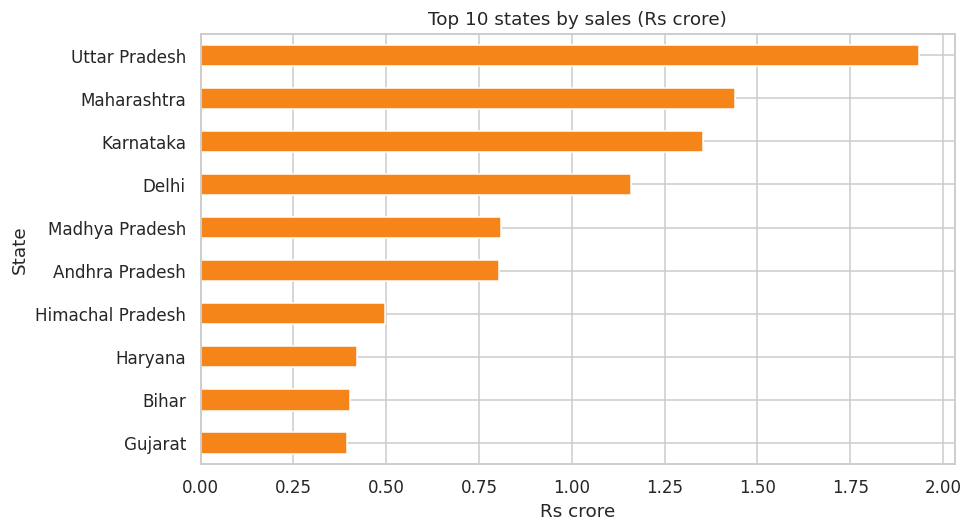

In [11]:
state_sales = df.groupby('State')['Amount'].sum().sort_values(ascending=False)
print((state_sales.head(5) / total * 100).round(1))

plt.figure(figsize=(9, 5))
(state_sales.head(10)[::-1]/1e7).plot(kind='barh', color='#f58518')
plt.title('Top 10 states by sales (Rs crore)'); plt.xlabel('Rs crore')
plt.tight_layout(); plt.savefig('../images/03_top_states.png'); plt.show()

In [12]:
zone_sales = df.groupby('Zone')['Amount'].sum().sort_values(ascending=False)
print((zone_sales / total * 100).round(1))

Zone
Central     39.2
Southern    25.1
Western     17.3
Northern    11.9
Eastern      6.6
Name: Amount, dtype: float64


## 7. What? Product categories

Product_Category
Food                     32.0
Clothing & Apparel       15.5
Electronics & Gadgets    14.7
Footwear & Shoes         14.7
Furniture                 5.1
Name: Amount, dtype: float64


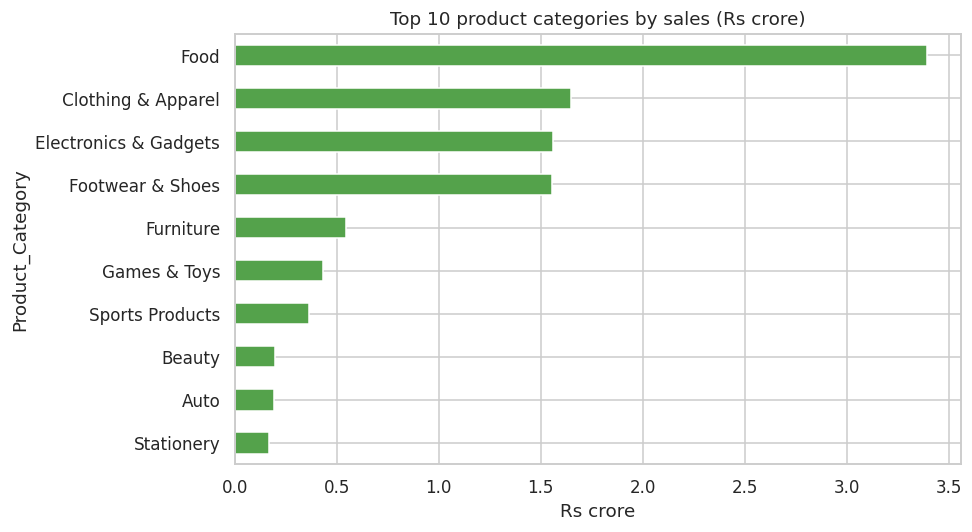

In [13]:
cat_sales = df.groupby('Product_Category')['Amount'].sum().sort_values(ascending=False)
print((cat_sales.head(5) / total * 100).round(1))

plt.figure(figsize=(9, 5))
(cat_sales.head(10)[::-1]/1e7).plot(kind='barh', color='#54a24b')
plt.title('Top 10 product categories by sales (Rs crore)'); plt.xlabel('Rs crore')
plt.tight_layout(); plt.savefig('../images/04_top_categories.png'); plt.show()

## 8. Occupation and marital status

Occupation
IT Sector     13.9
Healthcare    12.3
Aviation      11.9
Banking       10.1
Govt           8.0
Name: Amount, dtype: float64


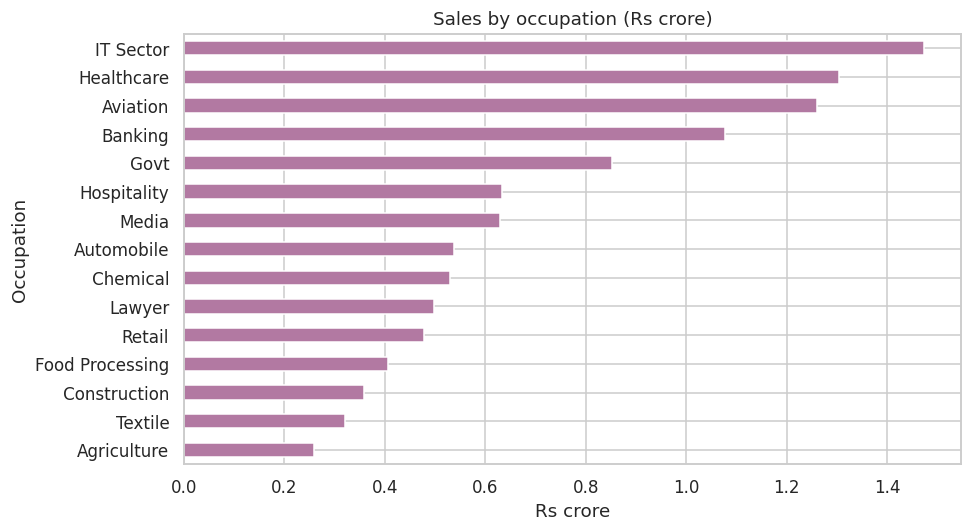

In [14]:
occ_sales = df.groupby('Occupation')['Amount'].sum().sort_values(ascending=False)
print((occ_sales.head(5) / total * 100).round(1))

plt.figure(figsize=(9, 5))
(occ_sales[::-1]/1e7).plot(kind='barh', color='#b279a2')
plt.title('Sales by occupation (Rs crore)'); plt.xlabel('Rs crore')
plt.tight_layout(); plt.savefig('../images/05_occupation.png'); plt.show()

Gender                   F           M
Marital_Status                        
0               43778560.0  18320176.0
1               30529122.0  13550970.0


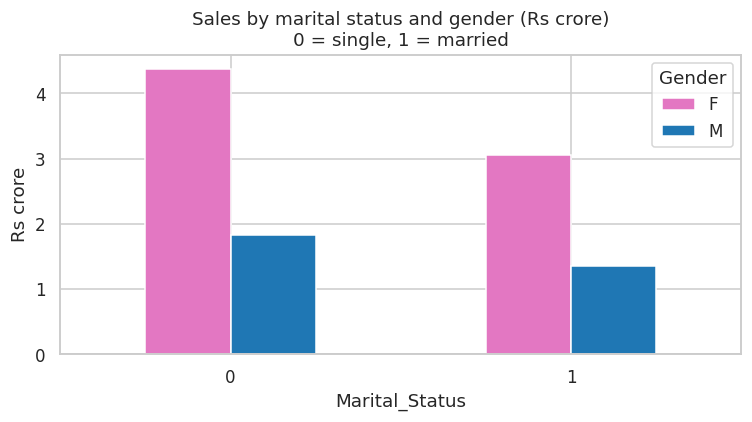

In [15]:
marital = df.groupby(['Marital_Status', 'Gender'])['Amount'].sum().unstack()
print(marital.round(0))
(marital/1e7).plot(kind='bar', figsize=(7,4), rot=0, color=['#e377c2','#1f77b4'])
plt.title('Sales by marital status and gender (Rs crore)\n0 = single, 1 = married'); plt.ylabel('Rs crore')
plt.tight_layout(); plt.savefig('../images/06_marital_gender.png'); plt.show()

## 9. Findings
- Women account for about **70%** of total sales.
- The **26-35** age group contributes about **40%** of sales.
- **Uttar Pradesh** is the top state (about 18%), followed by Maharashtra and Karnataka.
- **Food** is the top category (about 32%), then Clothing & Apparel and Electronics & Gadgets.
- Unmarried women are the biggest single customer segment (about **41%** of sales).